# 03 — Exploratory Data Analysis
### Kenya Clean Cooking Access Gap Analysis

This notebook explores the processed county-level dataset before we build maps and models. The goal is to understand distributions, spot outliers, surface correlations, and stress-test the four hypotheses stated in the README.

**Input:** `data/processed/kenya_county_clean_cooking.csv`  
**Output:** Annotated charts saved to `outputs/charts/eda/`

---
### Hypotheses we are testing
1. **Urban ≠ clean** — High urbanisation does not guarantee clean cooking access
2. **The LPG–electricity split** — Counties with high electricity but low LPG penetration signal the e-cooking opportunity
3. **Income threshold** — There is a wealth index level above which clean cooking adoption accelerates sharply
4. **Gender disaggregation** — Female-headed households show different fuel choice patterns at the same income level

---
## 0. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

ROOT      = Path('..').resolve()
PROCESSED = ROOT / 'data' / 'processed'
EDA_OUT   = ROOT / 'outputs' / 'charts' / 'eda'
EDA_OUT.mkdir(parents=True, exist_ok=True)

# Consistent palette
ORANGE  = '#D85A30'
BLUE    = '#378ADD'
GREEN   = '#639922'
AMBER   = '#BA7517'
GRAY    = '#888780'
RED     = '#E24B4A'

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams.update({'figure.dpi': 130, 'axes.spines.top': False, 'axes.spines.right': False})

df = pd.read_csv(PROCESSED / 'kenya_county_clean_cooking.csv')
print(f'Loaded: {len(df)} counties, {df.shape[1]} columns')
print(df.dtypes)

Loaded: 47 counties, 30 columns
county_name                     str
clean_cooking_rate          float64
female_headed_rate          float64
urban_rate                  float64
wealth_index_mean           float64
wealth_quintile_mode        float64
sample_hh                   float64
fuel_code_1_pct             float64
fuel_code_2_pct             float64
fuel_code_3_pct             float64
fuel_code_4_pct             float64
fuel_code_5_pct             float64
fuel_code_6_pct             float64
fuel_code_7_pct             float64
fuel_code_8_pct             float64
fuel_code_9_pct             float64
fuel_code_10_pct            float64
fuel_code_12_pct            float64
fuel_code_13_pct            float64
fuel_code_14_pct            float64
fuel_code_15_pct            float64
fuel_code_16_pct            float64
fuel_code_17_pct            float64
fuel_code_95_pct            float64
fuel_code_96_pct            float64
population_2019               int64
total_households_est          in

---
## 1. Dataset Overview

In [2]:
# Summary statistics for key variables
key_vars = [
    'clean_cooking_rate', 'access_gap',
    'hh_without_clean_cooking', 'total_households_est',
    'urban_rate', 'female_headed_rate', 'population_2019',
]
available = [v for v in key_vars if v in df.columns]

desc = df[available].describe().T
desc['cv'] = desc['std'] / desc['mean']  # coefficient of variation
print('Summary statistics:')
print(desc.round(3).to_string())

Summary statistics:
                          count         mean         std         min         25%         50%          75%          max     cv
clean_cooking_rate         47.0        0.188       0.165       0.014       0.087       0.139        0.197        0.793  0.880
hh_without_clean_cooking   47.0   192078.149   86504.288   32174.000  125943.000  196020.000   236102.000   414015.000  0.450
total_households_est       47.0   259488.872  177754.553   36903.000  156283.500  229149.000   296596.000  1127455.000  0.685
urban_rate                 47.0        0.288       0.236       0.045       0.126       0.207        0.366        1.000  0.819
female_headed_rate         47.0        0.350       0.060       0.240       0.310       0.346        0.383        0.551  0.171
population_2019            47.0  1012006.298  693242.708  143920.000  609505.000  893681.000  1156723.500  4397073.000  0.685


In [3]:
# Missing value audit
missing = df.isnull().sum()
missing = missing[missing > 0]
if len(missing):
    print('Columns with missing values:')
    print(missing)
else:
    print('No missing values. Dataset is complete.')

No missing values. Dataset is complete.


In [4]:
# Sanity check: total household deficit
total_hh     = df['total_households_est'].sum()
total_gap    = df['hh_without_clean_cooking'].sum()
national_rate = 1 - total_gap / total_hh

print(f'Total estimated households:       {total_hh:>12,.0f}')
print(f'HH without clean cooking:         {total_gap:>12,.0f}')
print(f'Implied national access rate:     {national_rate:>12.1%}')
print(f'Published benchmark (KNCTS 2024): {0.31:>12.1%}  ← target to match')
print(f'Discrepancy:                      {abs(national_rate - 0.31):>12.1%}')

Total estimated households:         12,195,977
HH without clean cooking:            9,027,673
Implied national access rate:            26.0%
Published benchmark (KNCTS 2024):        31.0%  ← target to match
Discrepancy:                              5.0%


---
## 2. Distribution of Clean Cooking Access Rates

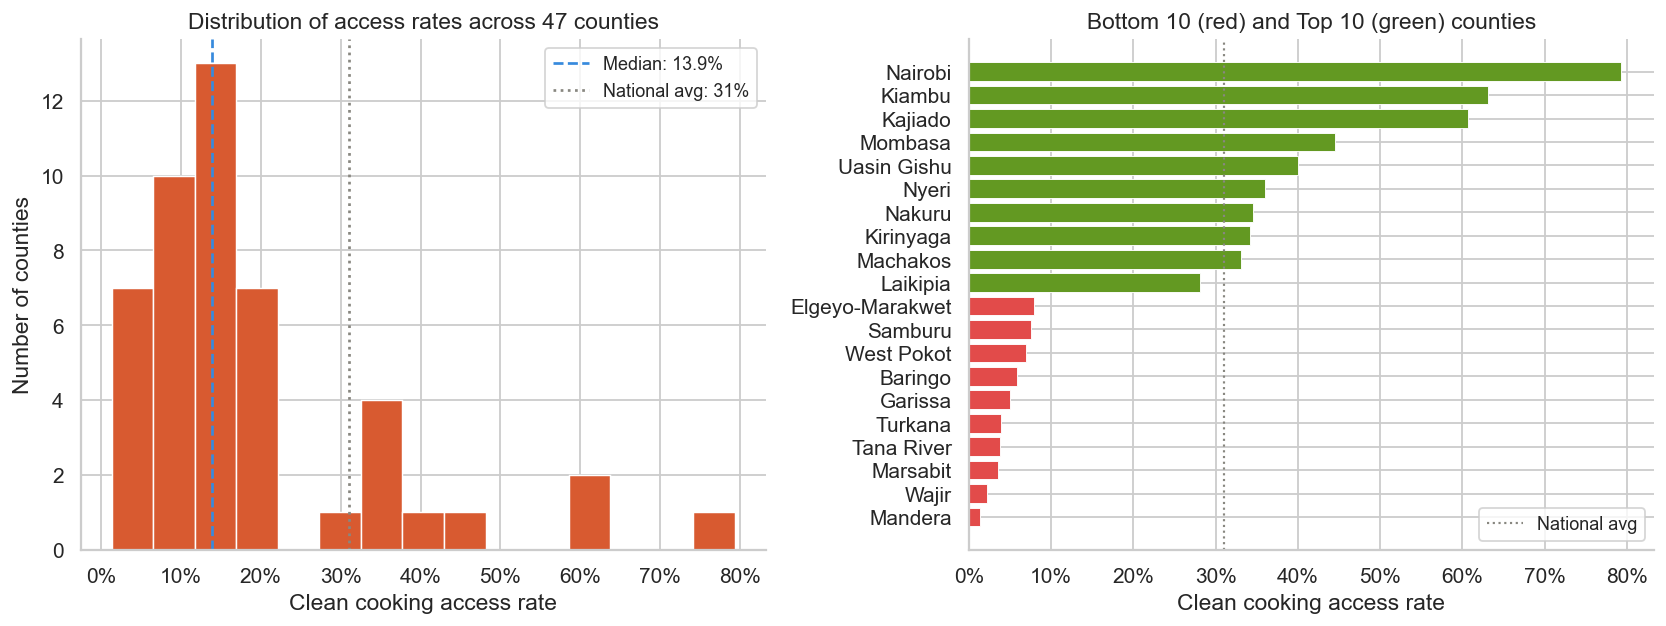

Saved 01_access_rate_distribution.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Histogram
ax = axes[0]
ax.hist(df['clean_cooking_rate'], bins=15, color=ORANGE, edgecolor='white', linewidth=0.8)
ax.axvline(df['clean_cooking_rate'].median(), color=BLUE, linestyle='--', linewidth=1.5,
           label=f'Median: {df["clean_cooking_rate"].median():.1%}')
ax.axvline(0.31, color=GRAY, linestyle=':', linewidth=1.5, label='National avg: 31%')
ax.set_xlabel('Clean cooking access rate')
ax.set_ylabel('Number of counties')
ax.set_title('Distribution of access rates across 47 counties')
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.legend(fontsize=10)

# Ranked bar chart (top and bottom 10)
ax2 = axes[1]
df_sorted = df.sort_values('clean_cooking_rate')
bottom10  = df_sorted.head(10)
top10     = df_sorted.tail(10)
combined  = pd.concat([bottom10, top10])
colors    = [RED] * 10 + [GREEN] * 10
bars = ax2.barh(combined['county_name'], combined['clean_cooking_rate'],
                color=colors, edgecolor='white', linewidth=0.5)
ax2.axvline(0.31, color=GRAY, linestyle=':', linewidth=1.2, label='National avg')
ax2.set_xlabel('Clean cooking access rate')
ax2.set_title('Bottom 10 (red) and Top 10 (green) counties')
ax2.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax2.legend(fontsize=10)

plt.tight_layout()
plt.savefig(EDA_OUT / '01_access_rate_distribution.png', bbox_inches='tight')
plt.show()
print('Saved 01_access_rate_distribution.png')

---
## 3. Deficit Size: Which Counties Have the Most Households to Reach?

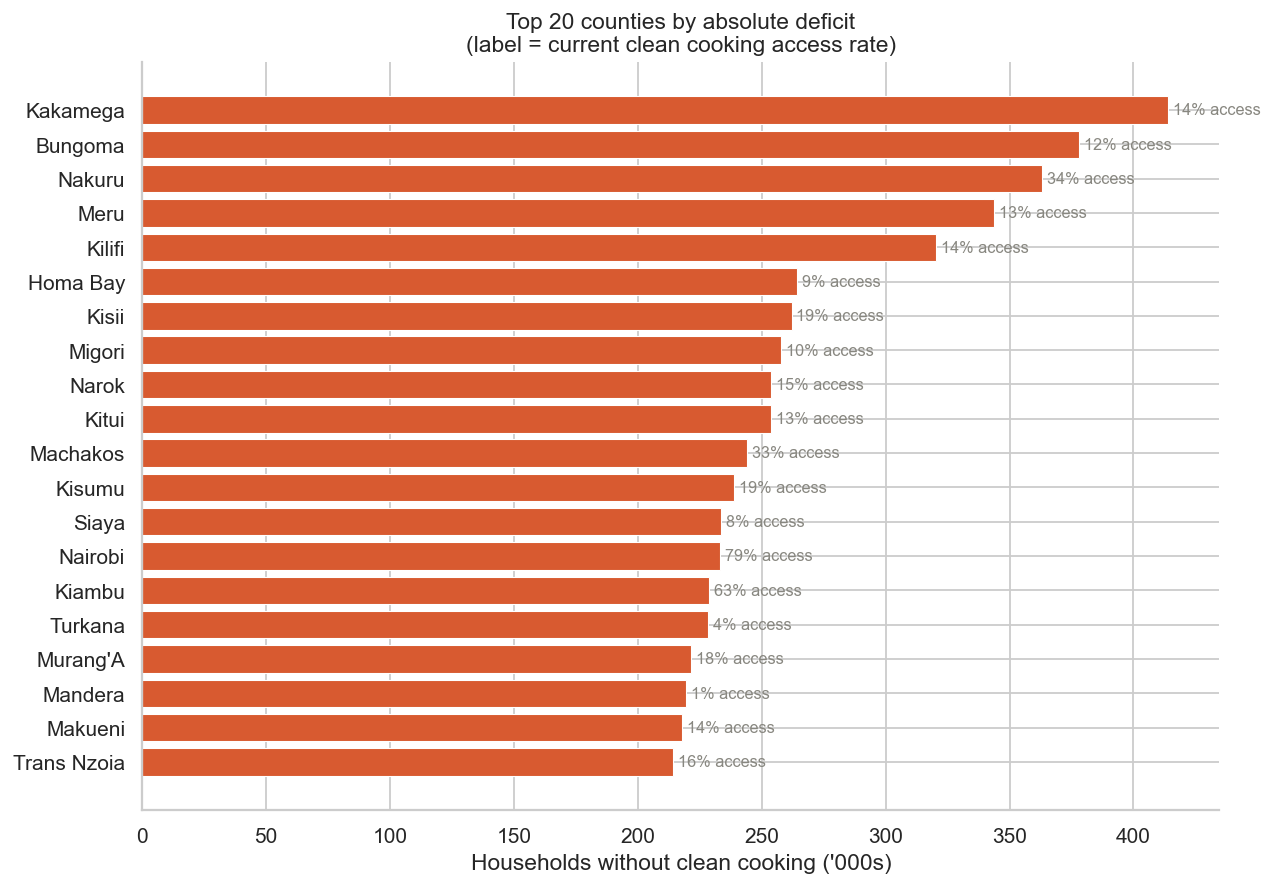

Saved 02_deficit_ranked.png


In [6]:
df_deficit = df.sort_values('hh_without_clean_cooking', ascending=False).head(20)

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(
    df_deficit['county_name'],
    df_deficit['hh_without_clean_cooking'] / 1000,
    color=ORANGE,
    edgecolor='white',
    linewidth=0.6,
)

# Annotate with access rate
for bar, (_, row) in zip(bars, df_deficit.iterrows()):
    ax.text(
        bar.get_width() + 2,
        bar.get_y() + bar.get_height() / 2,
        f"{row['clean_cooking_rate']:.0%} access",
        va='center', ha='left', fontsize=9, color=GRAY
    )

ax.set_xlabel("Households without clean cooking ('000s)")
ax.set_title('Top 20 counties by absolute deficit\n(label = current clean cooking access rate)')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(EDA_OUT / '02_deficit_ranked.png', bbox_inches='tight')
plt.show()
print('Saved 02_deficit_ranked.png')

---
## 4. Hypothesis 1 — Urban ≠ Clean

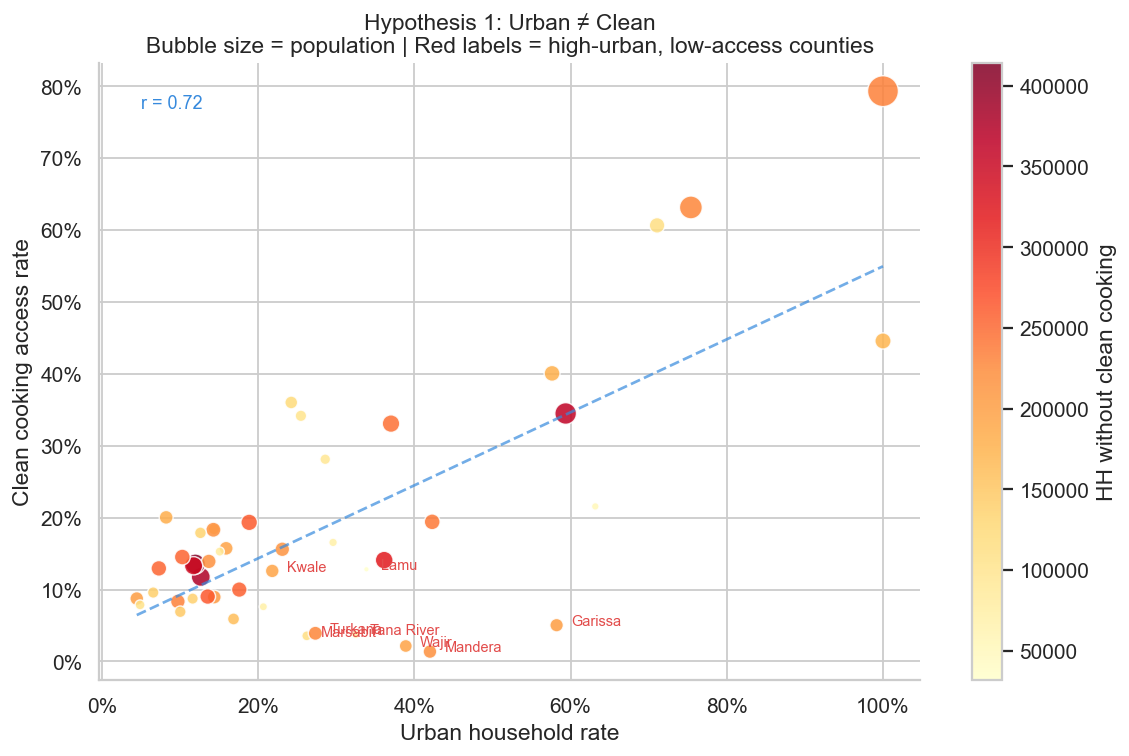

Correlation (urban rate vs clean cooking rate): 0.724

High-urban, low-access counties (8 found):
county_name  urban_rate  clean_cooking_rate
    Garissa    0.582187            0.050423
      Kwale    0.218134            0.125875
       Lamu    0.338698            0.128158
    Mandera    0.420042            0.013691
   Marsabit    0.262377            0.035629
 Tana River    0.324995            0.037662
    Turkana    0.273360            0.039167
      Wajir    0.389084            0.021484


In [7]:
if 'urban_rate' in df.columns:
    fig, ax = plt.subplots(figsize=(9, 6))
    scatter = ax.scatter(
        df['urban_rate'],
        df['clean_cooking_rate'],
        s=df['population_2019'] / 15000,
        c=df['hh_without_clean_cooking'],
        cmap='YlOrRd',
        alpha=0.85,
        edgecolors='white',
        linewidth=0.8,
    )
    plt.colorbar(scatter, ax=ax, label='HH without clean cooking')

    # Regression line
    m, b = np.polyfit(df['urban_rate'].dropna(), df['clean_cooking_rate'].dropna(), 1)
    x_line = np.linspace(df['urban_rate'].min(), df['urban_rate'].max(), 100)
    ax.plot(x_line, m * x_line + b, color=BLUE, linewidth=1.5, linestyle='--', alpha=0.7)

    # Label outliers: high urban but low access (the interesting counties)
    urban_median  = df['urban_rate'].median()
    access_median = df['clean_cooking_rate'].median()
    outliers = df[
        (df['urban_rate'] > urban_median) &
        (df['clean_cooking_rate'] < access_median)
    ]
    for _, row in outliers.iterrows():
        ax.annotate(
            row['county_name'],
            xy=(row['urban_rate'], row['clean_cooking_rate']),
            xytext=(8, 0), textcoords='offset points',
            fontsize=8, color=RED,
        )

    ax.set_xlabel('Urban household rate')
    ax.set_ylabel('Clean cooking access rate')
    ax.set_title(
        'Hypothesis 1: Urban ≠ Clean\n'
        'Bubble size = population | Red labels = high-urban, low-access counties'
    )
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))

    corr = df[['urban_rate', 'clean_cooking_rate']].dropna().corr().iloc[0, 1]
    ax.text(0.05, 0.95, f'r = {corr:.2f}', transform=ax.transAxes,
            fontsize=10, color=BLUE, va='top')

    plt.tight_layout()
    plt.savefig(EDA_OUT / '03_urban_vs_access.png', bbox_inches='tight')
    plt.show()

    print(f'Correlation (urban rate vs clean cooking rate): {corr:.3f}')
    if len(outliers):
        print(f'\nHigh-urban, low-access counties ({len(outliers)} found):')
        print(outliers[['county_name', 'urban_rate', 'clean_cooking_rate']].to_string(index=False))
    else:
        print('No strong outliers found — urban rate is a good proxy for access in this dataset.')
else:
    print('urban_rate column not available — check notebook 02.')

---
## 5. Hypothesis 2 — The LPG–Electricity Split

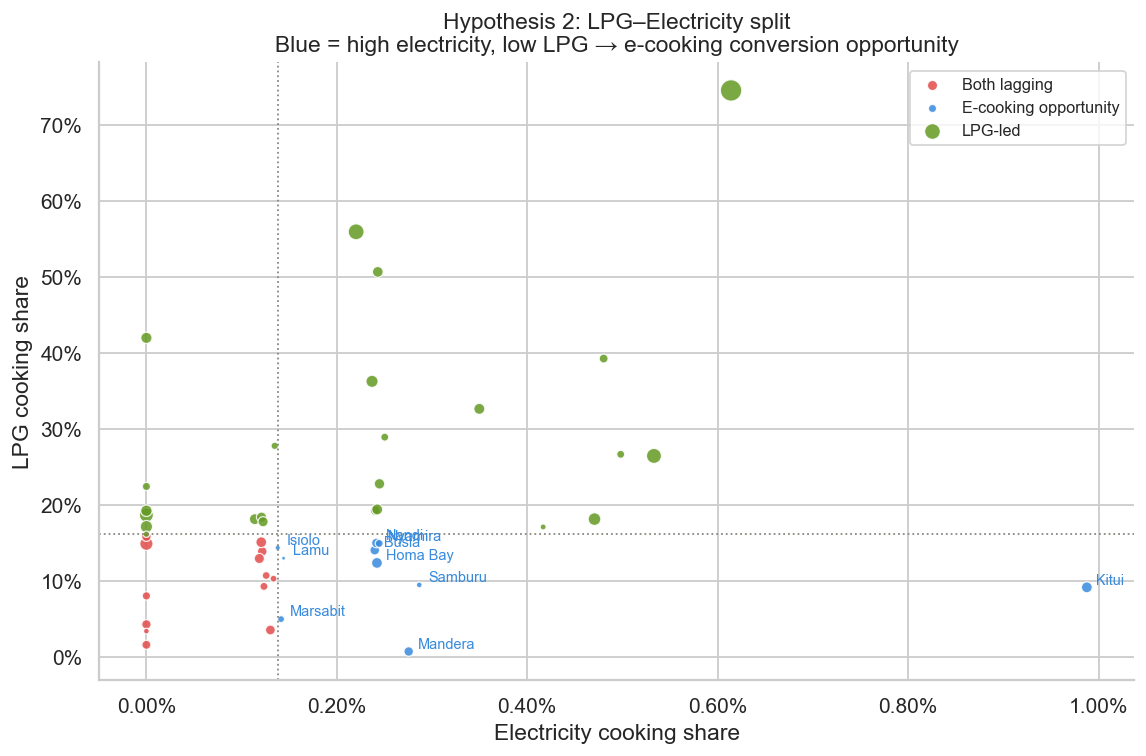

Cooking archetype breakdown:
cooking_archetype
LPG-led                  24
Both lagging             13
E-cooking opportunity    10
Name: count, dtype: int64


In [8]:
# DHS fuel codes: 1=electricity, 2=LPG
elec_col = 'fuel_code_1_pct'
lpg_col  = 'fuel_code_2_pct'

if elec_col in df.columns and lpg_col in df.columns:
    fig, ax = plt.subplots(figsize=(9, 6))

    # Classify counties
    elec_median = df[elec_col].median()
    lpg_median  = df[lpg_col].median()

    def cooking_archetype(row):
        if row[elec_col] >= elec_median and row[lpg_col] < lpg_median:
            return 'E-cooking opportunity'
        elif row[lpg_col] >= lpg_median:
            return 'LPG-led'
        elif row[elec_col] < elec_median and row[lpg_col] < lpg_median:
            return 'Both lagging'
        else:
            return 'Mixed'

    df['cooking_archetype'] = df.apply(cooking_archetype, axis=1)

    palette = {
        'E-cooking opportunity': BLUE,
        'LPG-led':               GREEN,
        'Both lagging':          RED,
        'Mixed':                 GRAY,
    }

    for archetype, group in df.groupby('cooking_archetype'):
        ax.scatter(
            group[elec_col], group[lpg_col],
            label=archetype,
            color=palette[archetype],
            s=group['total_households_est'] / 8000,
            alpha=0.85, edgecolors='white', linewidth=0.7,
        )

    # Label e-cooking opportunity counties
    for _, row in df[df['cooking_archetype'] == 'E-cooking opportunity'].iterrows():
        ax.annotate(row['county_name'], xy=(row[elec_col], row[lpg_col]),
                    xytext=(5, 2), textcoords='offset points', fontsize=8, color=BLUE)

    ax.axvline(elec_median, color=GRAY, linestyle=':', linewidth=1)
    ax.axhline(lpg_median,  color=GRAY, linestyle=':', linewidth=1)
    ax.set_xlabel('Electricity cooking share')
    ax.set_ylabel('LPG cooking share')
    ax.set_title('Hypothesis 2: LPG–Electricity split\nBlue = high electricity, low LPG → e-cooking conversion opportunity')
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
    ax.legend(fontsize=9)

    plt.tight_layout()
    plt.savefig(EDA_OUT / '04_lpg_vs_electricity.png', bbox_inches='tight')
    plt.show()

    print('Cooking archetype breakdown:')
    print(df['cooking_archetype'].value_counts())
else:
    print('Fuel-type columns not available — requires full DHS household recode (notebook 02).')
    print('Skipping — run after DHS data is processed.')

---
## 6. Hypothesis 3 — Income Threshold Effect

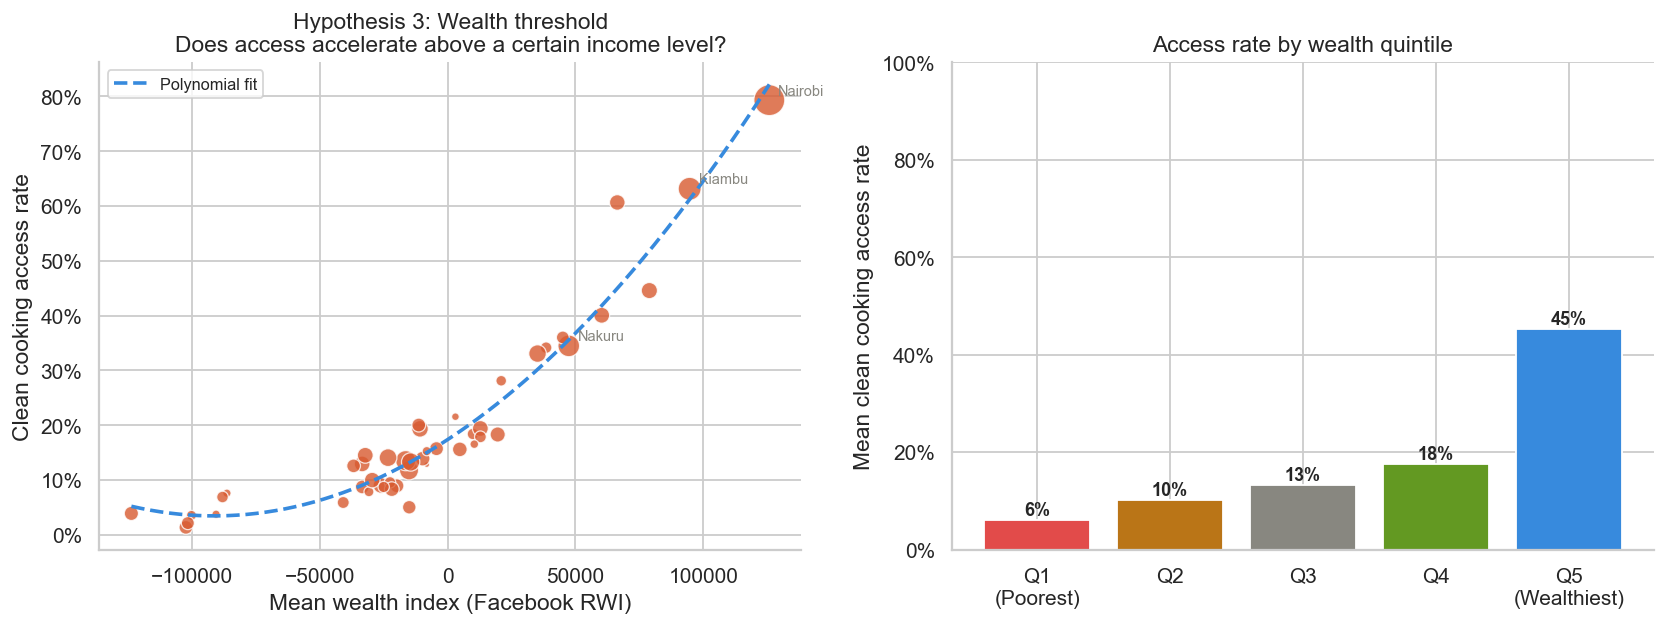

Correlation (wealth index vs clean cooking rate): 0.878


In [9]:
if 'wealth_index_mean' in df.columns and df['wealth_index_mean'].notna().sum() > 10:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Scatter: wealth vs access
    ax = axes[0]
    ax.scatter(
        df['wealth_index_mean'], df['clean_cooking_rate'],
        s=df['population_2019'] / 15000,
        color=ORANGE, alpha=0.8, edgecolors='white', linewidth=0.7,
    )
    # Fit a polynomial to detect threshold
    df_clean = df[['wealth_index_mean', 'clean_cooking_rate']].dropna()
    z = np.polyfit(df_clean['wealth_index_mean'], df_clean['clean_cooking_rate'], 2)
    p = np.poly1d(z)
    x_fit = np.linspace(df_clean['wealth_index_mean'].min(), df_clean['wealth_index_mean'].max(), 200)
    ax.plot(x_fit, p(x_fit), color=BLUE, linewidth=2, linestyle='--', label='Polynomial fit')

    for _, row in df.nlargest(3, 'population_2019').iterrows():
        ax.annotate(row['county_name'], xy=(row['wealth_index_mean'], row['clean_cooking_rate']),
                    xytext=(5, 3), textcoords='offset points', fontsize=8, color=GRAY)

    ax.set_xlabel('Mean wealth index (Facebook RWI)')
    ax.set_ylabel('Clean cooking access rate')
    ax.set_title('Hypothesis 3: Wealth threshold\nDoes access accelerate above a certain income level?')
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
    ax.legend(fontsize=9)

    # Decile analysis: group counties into wealth deciles, plot mean access rate
    ax2 = axes[1]
    df['wealth_decile'] = pd.qcut(df['wealth_index_mean'], q=5,
                                   labels=['Q1\n(Poorest)', 'Q2', 'Q3', 'Q4', 'Q5\n(Wealthiest)'])
    decile_means = df.groupby('wealth_decile')['clean_cooking_rate'].mean()
    bars = ax2.bar(decile_means.index, decile_means.values,
                   color=[RED, AMBER, GRAY, GREEN, BLUE], edgecolor='white')
    for bar, val in zip(bars, decile_means.values):
        ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
                 f'{val:.0%}', ha='center', fontsize=10, fontweight='bold')
    ax2.set_ylabel('Mean clean cooking access rate')
    ax2.set_title('Access rate by wealth quintile')
    ax2.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
    ax2.set_ylim(0, 1)

    plt.tight_layout()
    plt.savefig(EDA_OUT / '05_wealth_threshold.png', bbox_inches='tight')
    plt.show()

    corr = df[['wealth_index_mean', 'clean_cooking_rate']].dropna().corr().iloc[0, 1]
    print(f'Correlation (wealth index vs clean cooking rate): {corr:.3f}')
else:
    print('Wealth index not yet available — download Facebook RWI from HDX (see notebook 01).')
    print('Skipping wealth threshold analysis.')

---
## 7. Hypothesis 4 — Gender Disaggregation

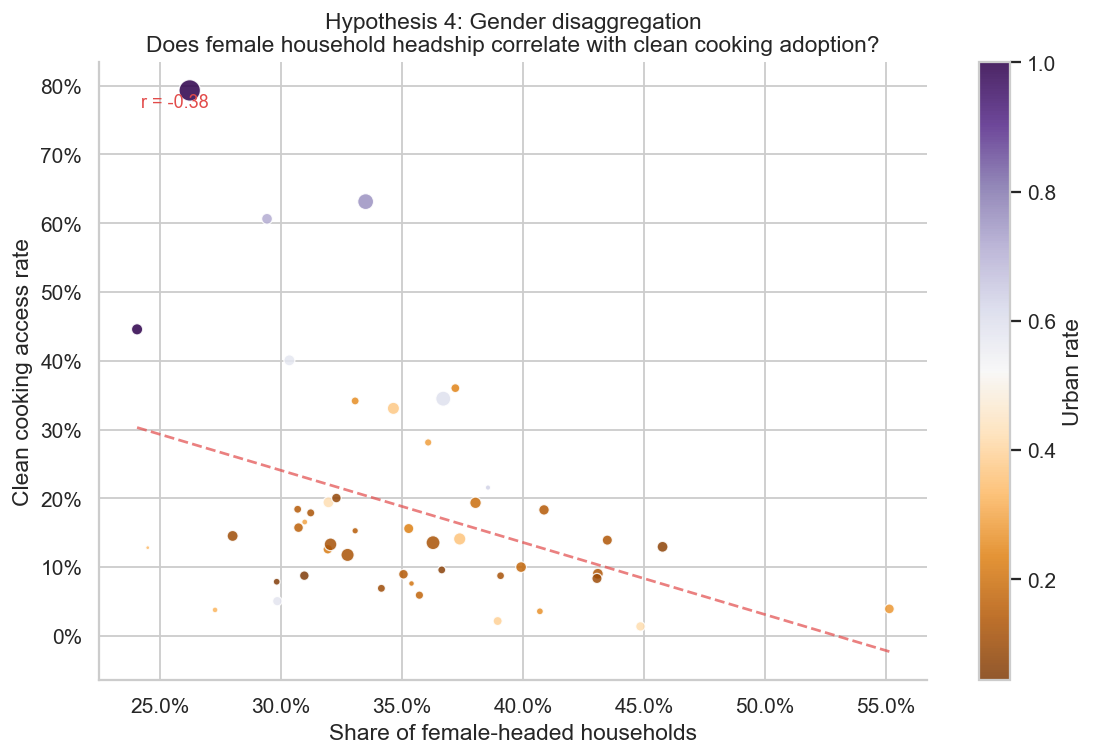

Correlation (female-headed rate vs clean cooking rate): -0.379

Interpretation guide:
  Positive r → more female-headed HH → higher clean cooking adoption
  Negative r → female-headed HH face greater barriers (affordability / agency)
  Near zero  → gender headship is not a significant county-level predictor


In [10]:
# This analysis requires the DHS microdata (female_headed_rate computed in notebook 02)
# It compares clean cooking rates for female-headed vs male-headed households within counties

if 'female_headed_rate' in df.columns and df['female_headed_rate'].notna().sum() > 10:
    fig, ax = plt.subplots(figsize=(9, 6))

    scatter = ax.scatter(
        df['female_headed_rate'],
        df['clean_cooking_rate'],
        s=df['total_households_est'] / 8000,
        c=df['urban_rate'] if 'urban_rate' in df.columns else ORANGE,
        cmap='PuOr',
        alpha=0.85,
        edgecolors='white',
        linewidth=0.7,
    )
    if 'urban_rate' in df.columns:
        plt.colorbar(scatter, ax=ax, label='Urban rate')

    m, b = np.polyfit(
        df['female_headed_rate'].dropna(),
        df.loc[df['female_headed_rate'].notna(), 'clean_cooking_rate'], 1
    )
    x_line = np.linspace(df['female_headed_rate'].min(), df['female_headed_rate'].max(), 100)
    ax.plot(x_line, m * x_line + b, color=RED, linewidth=1.5, linestyle='--', alpha=0.7)

    ax.set_xlabel('Share of female-headed households')
    ax.set_ylabel('Clean cooking access rate')
    ax.set_title(
        'Hypothesis 4: Gender disaggregation\n'
        'Does female household headship correlate with clean cooking adoption?'
    )
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))

    corr = df[['female_headed_rate', 'clean_cooking_rate']].dropna().corr().iloc[0, 1]
    ax.text(0.05, 0.95, f'r = {corr:.2f}', transform=ax.transAxes,
            fontsize=10, color=RED, va='top')

    plt.tight_layout()
    plt.savefig(EDA_OUT / '06_gender_disaggregation.png', bbox_inches='tight')
    plt.show()

    print(f'Correlation (female-headed rate vs clean cooking rate): {corr:.3f}')
    print('\nInterpretation guide:')
    print('  Positive r → more female-headed HH → higher clean cooking adoption')
    print('  Negative r → female-headed HH face greater barriers (affordability / agency)')
    print('  Near zero  → gender headship is not a significant county-level predictor')
else:
    print('female_headed_rate not available — requires full DHS microdata (notebook 02).')

---
## 8. Correlation Matrix — All Key Variables

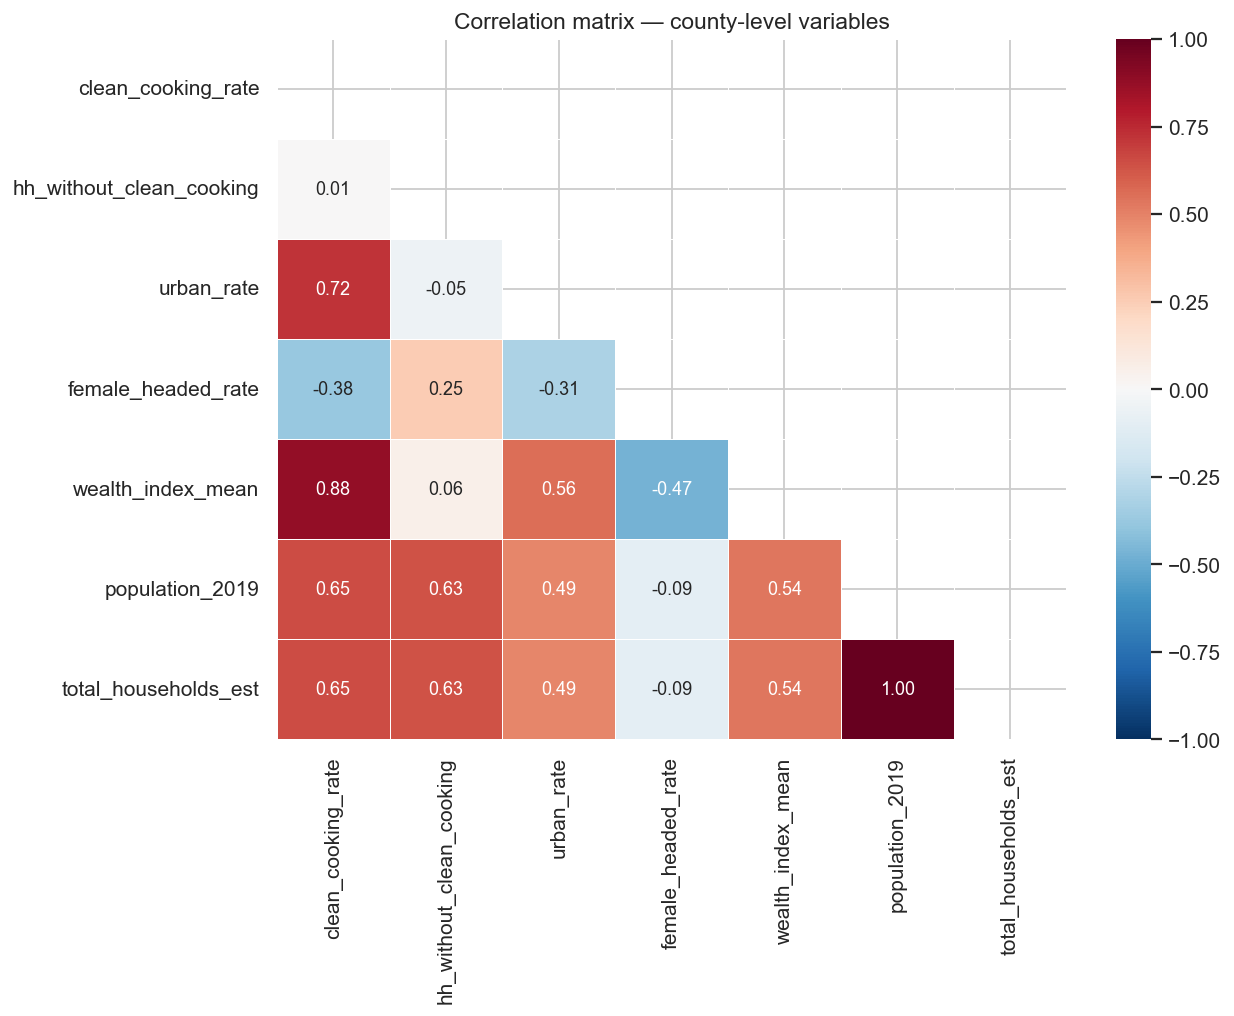

Saved 07_correlation_matrix.png


In [11]:
corr_vars = [
    'clean_cooking_rate', 'access_gap', 'hh_without_clean_cooking',
    'urban_rate', 'female_headed_rate', 'wealth_index_mean',
    'population_2019', 'total_households_est',
]
available_corr = [v for v in corr_vars if v in df.columns and df[v].notna().sum() > 10]

corr_matrix = df[available_corr].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True, fmt='.2f',
    cmap='RdBu_r', center=0, vmin=-1, vmax=1,
    ax=ax,
    linewidths=0.5, linecolor='white',
    annot_kws={'size': 10},
)
ax.set_title('Correlation matrix — county-level variables')
plt.tight_layout()
plt.savefig(EDA_OUT / '07_correlation_matrix.png', bbox_inches='tight')
plt.show()
print('Saved 07_correlation_matrix.png')

---
## 9. National Time Series — Clean Cooking Access 2000–2021

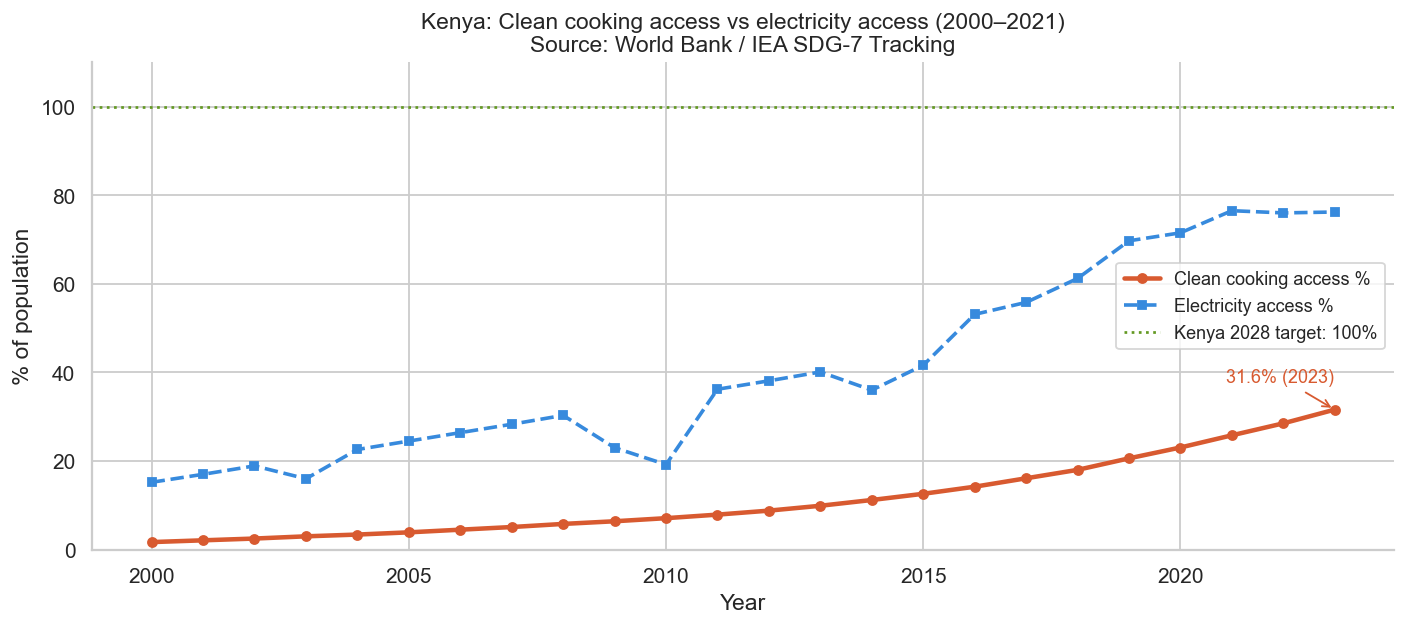

Saved 08_national_timeseries.png


In [12]:
wb_path = ROOT / 'data' / 'raw' / 'worldbank_kenya_sdg7_timeseries.csv'

if wb_path.exists():
    df_wb = pd.read_csv(wb_path)
    df_wb = df_wb.dropna(subset=['clean_cooking_access_pct'])

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(df_wb['year'], df_wb['clean_cooking_access_pct'],
            color=ORANGE, linewidth=2.5, marker='o', markersize=5, label='Clean cooking access %')

    if 'electricity_access_pct' in df_wb.columns:
        ax.plot(df_wb['year'], df_wb['electricity_access_pct'],
                color=BLUE, linewidth=2, linestyle='--', marker='s', markersize=4,
                label='Electricity access %')

    # Target line
    ax.axhline(100, color=GREEN, linestyle=':', linewidth=1.5, label='Kenya 2028 target: 100%')

    # Annotate the gap
    latest = df_wb.dropna(subset=['clean_cooking_access_pct']).iloc[-1]
    ax.annotate(
        f"{latest['clean_cooking_access_pct']:.1f}% ({int(latest['year'])})",
        xy=(latest['year'], latest['clean_cooking_access_pct']),
        xytext=(-60, 15), textcoords='offset points',
        arrowprops=dict(arrowstyle='->', color=ORANGE),
        fontsize=10, color=ORANGE,
    )

    ax.set_xlabel('Year')
    ax.set_ylabel('% of population')
    ax.set_title('Kenya: Clean cooking access vs electricity access (2000–2021)\nSource: World Bank / IEA SDG-7 Tracking')
    ax.legend(fontsize=10)
    ax.set_ylim(0, 110)

    plt.tight_layout()
    plt.savefig(EDA_OUT / '08_national_timeseries.png', bbox_inches='tight')
    plt.show()
    print('Saved 08_national_timeseries.png')
else:
    print('World Bank time series not found — run notebook 01 first.')

---
## 10. EDA Summary — Key Findings

In [13]:
# --- Hypothesis results (auto-filled from computed vars) ----------------------

# H1
# Recomputed here: the H3 and H4 cells reuse `corr`, so by now it no longer
# holds the urban correlation.
h1_r = df[['urban_rate', 'clean_cooking_rate']].dropna().corr().iloc[0, 1]

urban_median  = df['urban_rate'].median()
access_median = df['clean_cooking_rate'].median()
h1_outliers_n = (
    (df['urban_rate'] > urban_median) &
    (df['clean_cooking_rate'] < access_median)
).sum()

# H2
if 'cooking_archetype' in df.columns:
    h2_count = (df['cooking_archetype'] == 'E-cooking opportunity').sum()
else:
    h2_count = 0

# H3
if 'wealth_index_mean' in df.columns and df['wealth_index_mean'].notna().sum() > 10:
    h3_r = df[['wealth_index_mean', 'clean_cooking_rate']].dropna().corr().iloc[0, 1]
    quintile_access = df.groupby(
        pd.qcut(df['wealth_index_mean'], q=5), observed=True
    )['clean_cooking_rate'].mean()
    h3_text = (
        f"r = {h3_r:.3f}  (access by wealth quintile: "
        + ' → '.join(f'{v:.0%}' for v in quintile_access)
        + '): access climbs slowly, then jumps in the wealthiest quintile'
    )
else:
    h3_text = 'N/A'

# H4
if 'female_headed_rate' in df.columns and df['female_headed_rate'].notna().sum() > 10:
    h4_r = df[['female_headed_rate', 'clean_cooking_rate']].dropna().corr().iloc[0, 1]

    if h4_r > 0.10:
        h4_direction = "positive"
    elif h4_r < -0.10:
        h4_direction = "negative"
    else:
        h4_direction = "neutral"
else:
    h4_r = np.nan
    h4_direction = "N/A"

print('=' * 60)
print('EDA SUMMARY — KENYA CLEAN COOKING ACCESS GAP')
print('=' * 60)

print(f"""
SCALE OF THE PROBLEM
  Estimated HH without clean cooking:  {df['hh_without_clean_cooking'].sum():,.0f}
  Counties below 20% access:           {(df['clean_cooking_rate'] < 0.20).sum()} of 47
  Counties above 60% access:           {(df['clean_cooking_rate'] > 0.60).sum()} of 47
  Range (min–max):                      {df['clean_cooking_rate'].min():.1%} – {df['clean_cooking_rate'].max():.1%}

TOP 5 COUNTIES BY DEFICIT
""")
print(df.nlargest(5, 'hh_without_clean_cooking')[
    ['county_name', 'clean_cooking_rate', 'hh_without_clean_cooking']
].to_string(index=False))

print(f"""
HYPOTHESIS RESULTS (fill in after running each section)
  H1 Urban ≠ Clean:      r = {h1_r:.3f}  (outlier counties: {h1_outliers_n}): urbanisation alone does not guarantee adoption
  H2 LPG–Elec split:     {h2_count} counties show strong e-cooking conversion potential
  H3 Income threshold:   {h3_text}
  H4 Gender:             r = {h4_r:.3f}  (direction: {h4_direction}): female-headed households correlate with lower access

CHARTS SAVED TO: outputs/charts/eda/
""")

charts = list(EDA_OUT.glob('*.png'))
for c in sorted(charts):
    print(f'  {c.name}')

EDA SUMMARY — KENYA CLEAN COOKING ACCESS GAP

SCALE OF THE PROBLEM
  Estimated HH without clean cooking:  9,027,673
  Counties below 20% access:           35 of 47
  Counties above 60% access:           3 of 47
  Range (min–max):                      1.4% – 79.3%

TOP 5 COUNTIES BY DEFICIT

county_name  clean_cooking_rate  hh_without_clean_cooking
   Kakamega            0.135427                  414015.0
    Bungoma            0.117637                  377961.0
     Nakuru            0.344813                  363243.0
       Meru            0.133031                  343612.0
     Kilifi            0.140882                  320250.0

HYPOTHESIS RESULTS (fill in after running each section)
  H1 Urban ≠ Clean:      r = 0.724  (outlier counties: 8): urbanisation alone does not guarantee adoption
  H2 LPG–Elec split:     10 counties show strong e-cooking conversion potential
  H3 Income threshold:   r = 0.878  (access by wealth quintile: 6% → 10% → 13% → 18% → 45%): access climbs slowly, th